# 09 · Diabetes Prediction with Ensemble Learning (PBL III · Unit 5)
**Group 10 · Topic:** *Develop an intelligent diabetes prediction model using patient health records. Investigate the
effectiveness of different ensemble classifiers in identifying individuals at risk of diabetes.*

**Dataset:** Diabetes Prediction Dataset (100,000 patient records: demographics, comorbidities, smoking history, BMI,
HbA1c and blood glucose; target = diabetes yes/no), https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset

**Requirements covered:** ≥ 3 ensemble algorithms (we implement 10), compared with baselines (Logistic Regression and
Decision Tree), evaluated with F1-score and ROC-AUC (plus precision, recall, PR-AUC, accuracy), 5-fold stratified
cross-validation and a held-out test set.

In [1]:
# --- Setup: works in this repo (run from code/notebooks) and in Google Colab ---
import subprocess, sys, importlib
for pkg in ["xgboost", "lightgbm", "catboost", "shap"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

import json, time, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings("ignore")

BASE = Path("..") if (Path("..") / "data" / "raw").exists() else Path(".")
RAW, PROCESSED, FIGURES, MODELS = BASE / "data/raw", BASE / "data/processed", BASE / "outputs/figures", BASE / "outputs/models"
for d in (RAW / "diabetes", PROCESSED, FIGURES, MODELS):
    d.mkdir(parents=True, exist_ok=True)

CSV = RAW / "diabetes" / "diabetes_prediction_dataset.csv"
if not CSV.exists():   # Colab: download with kagglehub (public dataset)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=False)
    import kagglehub
    src = Path(kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")) / "diabetes_prediction_dataset.csv"
    shutil.copy(src, CSV)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE, ORANGE, GREEN = SERIES[0], SERIES[1], SERIES[2]
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#ffffff"
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#9ec5f4", "#f0efec", "#f2a3a2", "#e34948", "#9e2323"])
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "text.color": INK, "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": mpl.cycler(color=SERIES)})

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight"); plt.show()

def save_json(obj, name):
    (MODELS / f"{name}.json").write_text(json.dumps(obj, indent=2, default=float))

SEED = 42
df_raw = pd.read_csv(CSV)
print(df_raw.shape)
df_raw.head()

(100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


## 1. Data audit

In [2]:
audit = pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "missing": df_raw.isna().sum(), "unique": df_raw.nunique(),
                      "min": df_raw.min(numeric_only=True), "max": df_raw.max(numeric_only=True)})
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Gender:", df_raw.gender.value_counts().to_dict())
print("Smoking history:", df_raw.smoking_history.value_counts().to_dict())
print("Diabetes prevalence:", round(df_raw.diabetes.mean(), 4))
audit

Exact duplicate rows: 3854
Gender: {'Female': 58552, 'Male': 41430, 'Other': 18}
Smoking history: {'No Info': 35816, 'never': 35095, 'former': 9352, 'current': 9286, 'not current': 6447, 'ever': 4004}
Diabetes prevalence: 0.085


,dtype,missing,unique,min,max
HbA1c_level,float64,0,18,3.50,9.00
age,float64,0,102,0.08,80.00
blood_glucose_level,int64,0,18,80.00,300.00
bmi,float64,0,4247,10.01,95.69
diabetes,int64,0,2,0.00,1.00
gender,str,0,3,NaN,NaN
heart_disease,int64,0,2,0.00,1.00
hypertension,int64,0,2,0.00,1.00
smoking_history,str,0,6,NaN,NaN


## 2. Cleaning
- **3,854 exact duplicate records** are removed; otherwise identical rows could appear in both training and test sets
  and inflate scores.
- **Gender "Other"** has only 18 records, too few to learn from; those rows are dropped.
- **Smoking history "No Info"** (≈ 36 %) is kept as its own category: whether smoking was recorded is itself informative,
  and imputing it would invent information.
- All numeric values are within clinically plausible ranges (age 0.08–80, BMI 10–96, HbA1c 3.5–9 %, glucose 80–300 mg/dL),
  so no outlier removal is applied (high values are genuine high-risk patients, not errors).

In [3]:
df = df_raw.drop_duplicates()
df = df[df.gender != "Other"].reset_index(drop=True)
print(f"Rows: {len(df_raw):,} → {len(df):,} | diabetes prevalence {df.diabetes.mean():.3%}")
df.to_csv(PROCESSED / "diabetes_clean.csv", index=False)
NUM = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
BIN = ["hypertension", "heart_disease"]
CAT = ["gender", "smoking_history"]
df[NUM].describe().T.round(2)

Rows: 100,000 → 96,128 | diabetes prevalence 8.824%


,count,mean,std,min,25%,50%,75%,max
age,96128.0,41.80,22.46,0.08,24.0,43.00,59.00,80.00
bmi,96128.0,27.32,6.77,10.01,23.4,27.32,29.86,95.69
HbA1c_level,96128.0,5.53,1.07,3.50,4.8,5.80,6.20,9.00
blood_glucose_level,96128.0,138.22,40.91,80.00,100.0,140.00,159.00,300.00


## 3. Exploratory data analysis

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


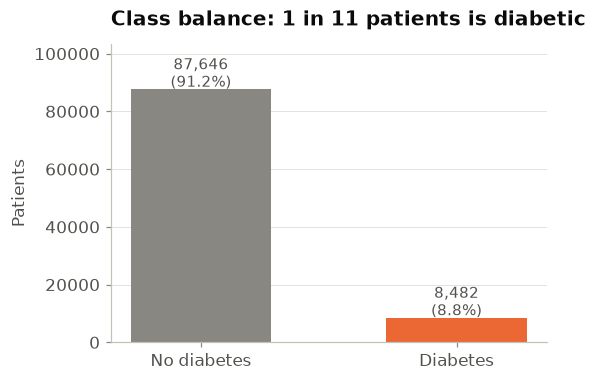

In [4]:
fig, ax = plt.subplots(figsize=(5.2, 3.6))
vc = df.diabetes.value_counts().sort_index()
ax.bar(["No diabetes", "Diabetes"], vc.values, color=[MUTED, ORANGE], width=0.55)
for i, v in enumerate(vc.values):
    ax.text(i, v + 900, f"{v:,}\n({v / vc.sum():.1%})", ha="center", color=INK_2, fontsize=9.5)
ax.set(title="Class balance: 1 in 11 patients is diabetic", ylabel="Patients", ylim=(0, vc.max() * 1.18))
ax.grid(axis="x", visible=False)
save(fig, "db_class_balance")

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


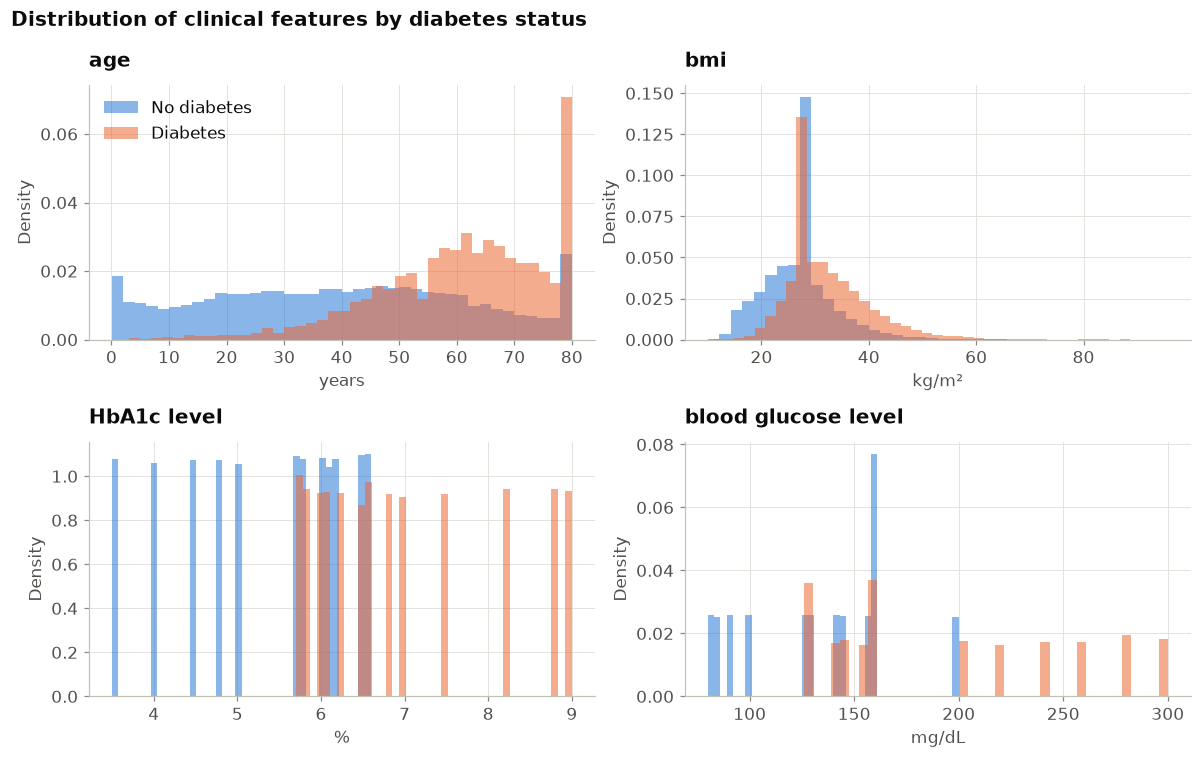

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col, unit in zip(axes.ravel(), NUM, ["years", "kg/m²", "%", "mg/dL"]):
    for cls, c, lab in [(0, BLUE, "No diabetes"), (1, ORANGE, "Diabetes")]:
        ax.hist(df.loc[df.diabetes == cls, col], bins=40, density=True, alpha=0.55, color=c, label=lab)
    ax.set(title=col.replace("_", " "), xlabel=unit, ylabel="Density")
axes[0, 0].legend()
fig.suptitle("Distribution of clinical features by diabetes status", x=0.01, ha="left", fontweight="semibold")
save(fig, "db_feature_distributions")

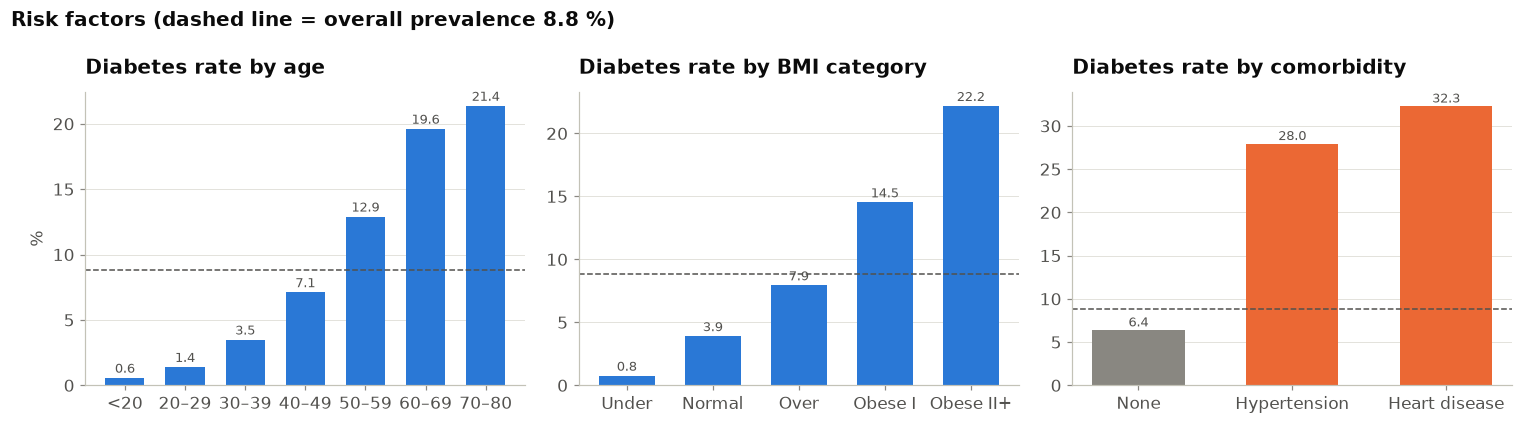

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
age_bins = pd.cut(df.age, [0, 20, 30, 40, 50, 60, 70, 81], right=False,
                  labels=["<20", "20–29", "30–39", "40–49", "50–59", "60–69", "70–80"])
r = df.groupby(age_bins, observed=True).diabetes.mean() * 100
axes[0].bar(r.index.astype(str), r.values, color=BLUE, width=0.65); axes[0].set(title="Diabetes rate by age", ylabel="%")
bmi_bins = pd.cut(df.bmi, [0, 18.5, 25, 30, 35, 100], labels=["Under", "Normal", "Over", "Obese I", "Obese II+"])
r = df.groupby(bmi_bins, observed=True).diabetes.mean() * 100
axes[1].bar(r.index.astype(str), r.values, color=BLUE, width=0.65); axes[1].set(title="Diabetes rate by BMI category")
comb = pd.Series({"None": df[(df.hypertension == 0) & (df.heart_disease == 0)].diabetes.mean(),
                  "Hypertension": df[df.hypertension == 1].diabetes.mean(),
                  "Heart disease": df[df.heart_disease == 1].diabetes.mean()}) * 100
axes[2].bar(comb.index, comb.values, color=[MUTED, ORANGE, ORANGE], width=0.6); axes[2].set(title="Diabetes rate by comorbidity")
for ax in axes:
    ax.axhline(df.diabetes.mean() * 100, color=INK_2, ls="--", lw=1); ax.grid(axis="x", visible=False)
    for p in ax.patches:
        ax.text(p.get_x() + p.get_width() / 2, p.get_height() + 0.4, f"{p.get_height():.1f}", ha="center", fontsize=8.5, color=INK_2)
fig.suptitle("Risk factors (dashed line = overall prevalence 8.8 %)", x=0.01, ha="left", fontweight="semibold")
save(fig, "db_risk_factors")

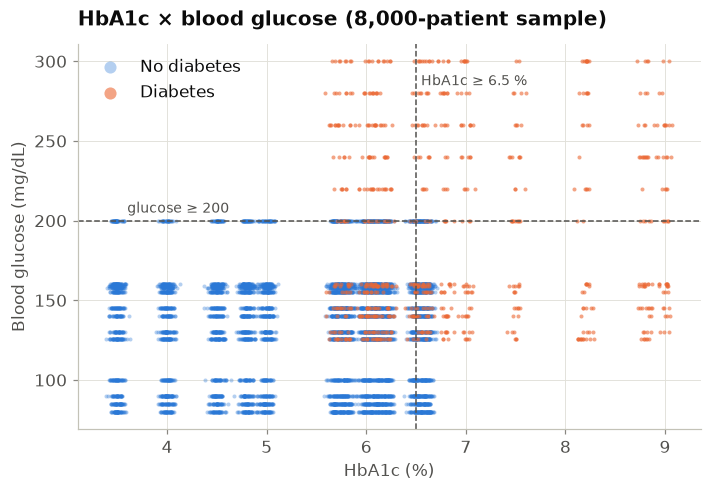

Patients with HbA1c > 6.6 or glucose > 200: 5.9% of all; diabetes rate among them 100.0%
Diabetics captured by that rule: 66.9%  (the rest are the hard cases)


In [7]:
fig, ax = plt.subplots(figsize=(6.6, 4.6))
smp = df.sample(8000, random_state=SEED)
jit = np.random.default_rng(0).normal(0, 0.04, len(smp))
for cls, c, lab in [(0, BLUE, "No diabetes"), (1, ORANGE, "Diabetes")]:
    m = smp.diabetes == cls
    ax.scatter(smp.HbA1c_level[m] + jit[m], smp.blood_glucose_level[m], s=7, alpha=0.35 if cls == 0 else 0.6, color=c,
               linewidths=0, label=lab)
ax.axvline(6.5, color=INK_2, ls="--", lw=1); ax.axhline(200, color=INK_2, ls="--", lw=1)
ax.text(6.55, 285, "HbA1c ≥ 6.5 %", fontsize=9, color=INK_2); ax.text(3.6, 205, "glucose ≥ 200", fontsize=9, color=INK_2)
ax.set(title="HbA1c × blood glucose (8,000-patient sample)", xlabel="HbA1c (%)", ylabel="Blood glucose (mg/dL)")
ax.legend(markerscale=3, loc="upper left")
save(fig, "db_hba1c_glucose")

high = (df.HbA1c_level > 6.6) | (df.blood_glucose_level > 200)
print(f"Patients with HbA1c > 6.6 or glucose > 200: {high.mean():.1%} of all; diabetes rate among them {df.diabetes[high].mean():.1%}")
print(f"Diabetics captured by that rule: {high[df.diabetes == 1].mean():.1%}  (the rest are the hard cases)")

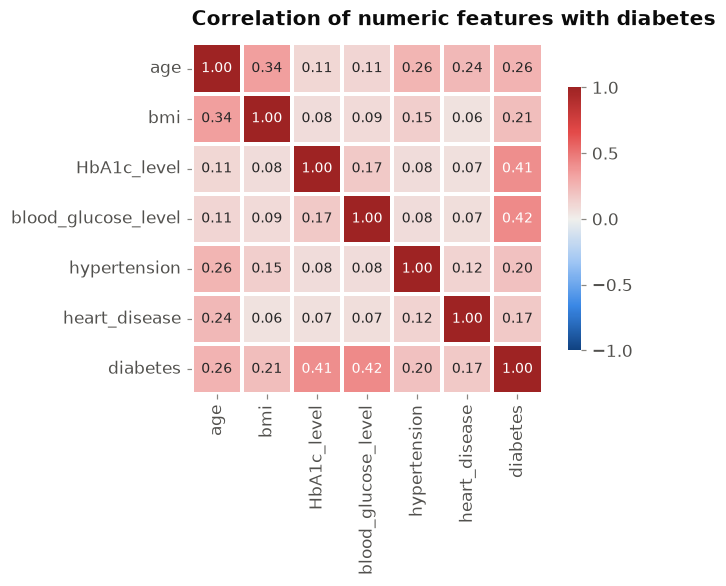

blood_glucose_level    0.424
HbA1c_level            0.406
age                    0.265
bmi                    0.215
hypertension           0.196
heart_disease          0.171
Name: diabetes, dtype: float64

In [8]:
enc = pd.get_dummies(df, columns=CAT, drop_first=False, dtype=float)
corr = df[NUM + BIN + ["diabetes"]].corr()
fig, ax = plt.subplots(figsize=(6.6, 5.4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1, square=True, linewidths=1.5, linecolor=SURFACE,
            cbar_kws={"shrink": 0.75}, ax=ax, annot_kws={"fontsize": 9})
ax.set(title="Correlation of numeric features with diabetes"); ax.grid(False)
save(fig, "db_correlation")
corr["diabetes"].drop("diabetes").sort_values(ascending=False).round(3)

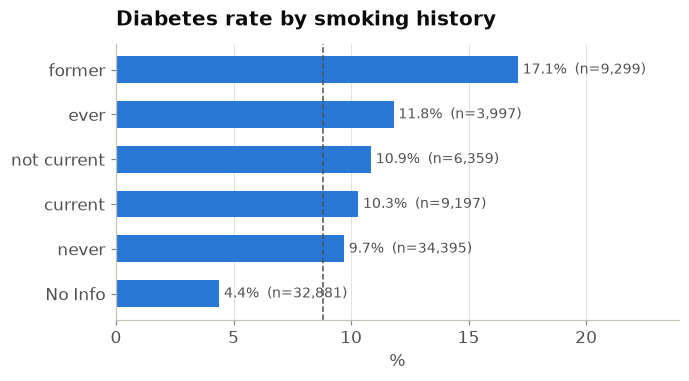

In [9]:
sm = df.groupby("smoking_history").diabetes.agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.barh(sm.index, sm["mean"] * 100, color=BLUE, height=0.6)
for y, (m, n) in enumerate(zip(sm["mean"], sm["size"])):
    ax.text(m * 100 + 0.2, y, f"{m:.1%}  (n={n:,})", va="center", fontsize=9, color=INK_2)
ax.axvline(df.diabetes.mean() * 100, color=INK_2, ls="--", lw=1)
ax.set(title="Diabetes rate by smoking history", xlabel="%", xlim=(0, sm["mean"].max() * 140))
ax.grid(axis="y", visible=False)
save(fig, "db_smoking")

**EDA insights**
1. **Imbalanced target**: ≈ 8.8 % diabetic after cleaning → accuracy is misleading (always "no" = 91 %); we focus on
   **F1** and **ROC-AUC / PR-AUC**, use stratified splits and tune the decision threshold.
2. **HbA1c and blood glucose are the dominant signals** (correlation 0.40 and 0.42 with diabetes). Above the clinical
   cut-offs (HbA1c > 6.6 %, glucose > 200) nearly every patient is diabetic, but a substantial share of diabetics have
   values below these cut-offs: those are the hard cases where combining many risk factors matters.
3. **Risk rises steeply with age, BMI, hypertension and heart disease**: non-linear, interacting effects that tree
   ensembles capture naturally.
4. Features have mixed types (continuous, binary, categorical) and different scales: trees are scale-invariant, while
   Logistic Regression needs standardisation and one-hot encoding.

## 4. Train / test split and preprocessing
- **Stratified 80 / 20 split** (`random_state = 42`), keeping 8.8 % positives in both sets. The test set is used once.
- One-hot encoding for `gender` and `smoking_history`; standardisation of numeric features (needed by Logistic
  Regression; harmless for trees). Both are inside a `Pipeline`, fitted on training folds only.
- **5-fold stratified cross-validation** on the training set for all model comparisons.

In [10]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, VotingClassifier, StackingClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, roc_curve, precision_recall_curve, brier_score_loss)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

X = df.drop(columns="diabetes"); y = df.diabetes.values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train {X_train.shape}, positives {y_train.mean():.3%} | Test {X_test.shape}, positives {y_test.mean():.3%}")
pre = ColumnTransformer([("num", StandardScaler(), NUM + BIN),
                         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pos_w = (y_train == 0).sum() / (y_train == 1).sum()

def P(model):
    return Pipeline([("pre", pre), ("model", model)])

Train (76902, 8), positives 8.824% | Test (19226, 8), positives 8.821%


## 5. Models: 2 baselines + 10 ensembles
| Family | Model | Idea |
|---|---|---|
| Baseline | Logistic Regression | linear decision boundary on standardised features |
| Baseline | Decision Tree (CART) | single tree, axis-aligned splits |
| Bagging | Bagging (CART) | average many trees trained on bootstrap samples → lower variance |
| Bagging | Random Forest | bagging + random feature subset at each split → decorrelated trees |
| Bagging | Extra Trees | random split thresholds too → even more variance reduction |
| Boosting | AdaBoost | re-weights misclassified samples; weighted vote of weak learners |
| Boosting | Gradient Boosting | each tree fits the gradient (residual) of the log-loss |
| Boosting | XGBoost | regularised gradient boosting, second-order optimisation |
| Boosting | LightGBM | histogram-based, leaf-wise gradient boosting |
| Boosting | CatBoost | ordered boosting with symmetric trees |
| Meta | Soft Voting | averages predicted probabilities of RF, XGBoost, LightGBM, CatBoost |
| Meta | Stacking | logistic-regression meta-learner on out-of-fold predictions of the same four |

In [11]:
def base_learners():
    return [("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED)),
            ("xgb", XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.9, colsample_bytree=0.9,
                                  eval_metric="logloss", n_jobs=-1, random_state=SEED)),
            ("lgbm", LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.9, subsample_freq=1,
                                    colsample_bytree=0.9, verbose=-1, n_jobs=-1, random_state=SEED)),
            ("cat", CatBoostClassifier(iterations=500, learning_rate=0.08, depth=6, verbose=0, random_seed=SEED,
                                       thread_count=-1))]

models = {
    "Logistic Regression": P(LogisticRegression(max_iter=2000)),
    "Decision Tree": P(DecisionTreeClassifier(random_state=SEED)),
    "Bagging": P(BaggingClassifier(DecisionTreeClassifier(random_state=SEED), n_estimators=200, n_jobs=-1, random_state=SEED)),
    "Random Forest": P(RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED)),
    "Extra Trees": P(ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED)),
    "AdaBoost": P(AdaBoostClassifier(n_estimators=300, learning_rate=0.5, random_state=SEED)),
    "Gradient Boosting": P(GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=SEED)),
    "XGBoost": P(dict(base_learners())["xgb"]),
    "LightGBM": P(dict(base_learners())["lgbm"]),
    "CatBoost": P(dict(base_learners())["cat"]),
    "Soft Voting": P(VotingClassifier(base_learners(), voting="soft", n_jobs=1)),
    "Stacking": P(StackingClassifier(base_learners(), final_estimator=LogisticRegression(max_iter=2000), cv=5,
                                     stack_method="predict_proba", n_jobs=1)),
}
FAMILY = {"Logistic Regression": "Baseline", "Decision Tree": "Baseline", "Bagging": "Bagging", "Random Forest": "Bagging",
          "Extra Trees": "Bagging", "AdaBoost": "Boosting", "Gradient Boosting": "Boosting", "XGBoost": "Boosting",
          "LightGBM": "Boosting", "CatBoost": "Boosting", "Soft Voting": "Meta-ensemble", "Stacking": "Meta-ensemble"}

## 6. 5-fold stratified cross-validation (training set)

In [12]:
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}
cv_rows, cv_f1_folds = [], {}
for name, model in models.items():
    t0 = time.time()
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=1)
    cv_f1_folds[name] = res["test_f1"]
    cv_rows.append({"Model": name, "Family": FAMILY[name],
                    **{f"CV {k}": res[f"test_{k}"].mean() for k in SCORING},
                    "CV F1 std": res["test_f1"].std(), "CV ROC-AUC std": res["test_roc_auc"].std(),
                    "CV time (s)": time.time() - t0})
    print(f"{name:20s} F1 {res['test_f1'].mean():.4f} ± {res['test_f1'].std():.4f} | ROC-AUC {res['test_roc_auc'].mean():.4f}")
cvres = pd.DataFrame(cv_rows).sort_values("CV f1", ascending=False).reset_index(drop=True)
cvres.to_csv(MODELS / "diabetes_cv_results.csv", index=False)
cvres.round(4)

Logistic Regression  F1 0.7296 ± 0.0060 | ROC-AUC 0.9620


Decision Tree        F1 0.7225 ± 0.0063 | ROC-AUC 0.8562


Bagging              F1 0.7897 ± 0.0068 | ROC-AUC 0.9682


Random Forest        F1 0.7994 ± 0.0040 | ROC-AUC 0.9699


Extra Trees          F1 0.7878 ± 0.0052 | ROC-AUC 0.9718


AdaBoost             F1 0.7992 ± 0.0049 | ROC-AUC 0.9759


... (3 outputs left out)

CatBoost             F1 0.8024 ± 0.0064 | ROC-AUC 0.9785


Soft Voting          F1 0.8030 ± 0.0047 | ROC-AUC 0.9779


Stacking             F1 0.8050 ± 0.0032 | ROC-AUC 0.9774


,Model,Family,CV accuracy,CV precision,CV recall,CV f1,CV roc_auc,CV pr_auc,CV F1 std,CV ROC-AUC std,CV time (s)
0,Gradient Boosting,Boosting,0.9707,0.9696,0.6895,0.8059,0.9795,0.8873,0.0030,0.0003,75.2774
1,Stacking,Meta-ensemble,0.9698,0.9344,0.7072,0.8050,0.9774,0.8857,0.0032,0.0009,192.3438
2,XGBoost,Boosting,0.9705,0.9708,0.6860,0.8038,0.9794,0.8885,0.0039,0.0004,3.4994
3,Soft Voting,Meta-ensemble,0.9704,0.9725,0.6839,0.8030,0.9779,0.8855,0.0047,0.0006,41.5880
4,LightGBM,Boosting,0.9700,0.9587,0.6904,0.8026,0.9782,0.8835,0.0033,0.0003,9.5542
5,CatBoost,Boosting,0.9700,0.9588,0.6899,0.8024,0.9785,0.8850,0.0064,0.0003,14.7565
6,Random Forest,Bagging,0.9701,0.9775,0.6762,0.7994,0.9699,0.8703,0.0040,0.0014,11.8294
7,AdaBoost,Boosting,0.9705,0.9987,0.6662,0.7992,0.9759,0.8764,0.0049,0.0009,33.9968
8,Bagging,Bagging,0.9673,0.9148,0.6948,0.7897,0.9682,0.8633,0.0068,0.0017,34.8778
9,Extra Trees,Bagging,0.9689,0.9883,0.6550,0.7878,0.9718,0.8705,0.0052,0.0008,9.2637


## 7. Held-out test set (default threshold 0.5)

In [13]:
test_rows, fitted, proba = [], {}, {}
for name, model in models.items():
    t0 = time.time(); model.fit(X_train, y_train); fit_s = time.time() - t0
    p = model.predict_proba(X_test)[:, 1]; pred = (p >= 0.5).astype(int)
    fitted[name], proba[name] = model, p
    test_rows.append({"Model": name, "Family": FAMILY[name], "Accuracy": accuracy_score(y_test, pred),
                      "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                      "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, p),
                      "PR-AUC": average_precision_score(y_test, p), "Brier": brier_score_loss(y_test, p), "Fit time (s)": fit_s})
test = pd.DataFrame(test_rows).sort_values("F1", ascending=False).reset_index(drop=True)
test.to_csv(MODELS / "diabetes_test_results.csv", index=False)
test.round(4)

,Model,Family,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,Fit time (s)
0,XGBoost,Boosting,0.9717,0.9721,0.6987,0.8130,0.9775,0.8821,0.0235,0.7591
1,Gradient Boosting,Boosting,0.9715,0.9674,0.7005,0.8126,0.9774,0.8812,0.0237,18.5808
2,Soft Voting,Meta-ensemble,0.9714,0.9728,0.6952,0.8109,0.9759,0.8787,0.0238,9.2925
3,Random Forest,Bagging,0.9715,0.9808,0.6910,0.8108,0.9661,0.8627,0.0249,3.2012
4,AdaBoost,Boosting,0.9717,0.9991,0.6798,0.8091,0.9745,0.8725,0.1102,7.9430
5,LightGBM,Boosting,0.9706,0.9579,0.6969,0.8068,0.9766,0.8790,0.0240,1.8734
6,Stacking,Meta-ensemble,0.9697,0.9252,0.7146,0.8064,0.9756,0.8789,0.0252,50.8647
7,CatBoost,Boosting,0.9704,0.9548,0.6969,0.8057,0.9766,0.8786,0.0241,3.4984
8,Bagging,Bagging,0.9682,0.9112,0.7081,0.7969,0.9633,0.8575,0.0265,11.7031
9,Extra Trees,Bagging,0.9695,0.9868,0.6633,0.7934,0.9684,0.8629,0.0274,2.4166


## 8. Hyperparameter tuning of the strongest boosting model
Randomised search (40 configurations × 5 folds, scored by PR-AUC, which focuses on the rare positive class) over the
LightGBM hyperparameters: number of trees, learning rate, leaves, depth, minimum child samples, row/column subsampling
and L1/L2 regularisation.

In [14]:
param_dist = {
    "model__n_estimators": [200, 400, 600, 800, 1000], "model__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.08, 0.1],
    "model__num_leaves": [15, 31, 63, 127], "model__max_depth": [-1, 4, 6, 8, 10],
    "model__min_child_samples": [10, 20, 40, 80], "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0], "model__reg_alpha": [0, 0.01, 0.1, 1.0],
    "model__reg_lambda": [0, 0.1, 1.0, 5.0],
}
search = RandomizedSearchCV(P(LGBMClassifier(subsample_freq=1, verbose=-1, n_jobs=-1, random_state=SEED)), param_dist,
                            n_iter=40, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=1, refit=True)
t0 = time.time(); search.fit(X_train, y_train); tune_s = time.time() - t0
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print(f"Best CV PR-AUC {search.best_score_:.4f} in {tune_s:.0f}s with", best_params)
tuned = search.best_estimator_
fitted["LightGBM (tuned)"] = tuned
proba["LightGBM (tuned)"] = tuned.predict_proba(X_test)[:, 1]

Best CV PR-AUC 0.8903 in 475s with {'subsample': 0.8, 'reg_lambda': 5.0, 'reg_alpha': 1.0, 'num_leaves': 63, 'n_estimators': 400, 'min_child_samples': 80, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


## 9. Final-model selection and decision-threshold optimisation (training data only)
- **Final model = the model with the highest 5-fold CV F1** (Section 6). It is chosen on training data only, so the
  test set never influences model selection.
- With 8.8 % positives the default 0.5 threshold may not maximise F1. For the final model and the main competitors we
  choose the threshold that maximises F1 on **out-of-fold predictions of the training set**, then apply it unchanged
  to the test set (no test leakage).

In [15]:
def best_threshold(model):
    oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
    pr, rc, th = precision_recall_curve(y_train, oof)
    f1s = 2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12)
    return float(th[np.argmax(f1s)]), oof

final_name = cvres.iloc[0]["Model"]
print("Final model (highest CV F1):", final_name)
thr_rows, thresholds = [], {}
candidates = ["Logistic Regression", final_name, "XGBoost", "Random Forest", "CatBoost", "Stacking", "LightGBM (tuned)"]
for name in dict.fromkeys(candidates):
    mdl = tuned if name == "LightGBM (tuned)" else models[name]
    t, oof = best_threshold(mdl)
    thresholds[name] = t
    p = proba[name]; pred = (p >= t).astype(int)
    thr_rows.append({"Model": name, "Threshold": t, "Accuracy": accuracy_score(y_test, pred),
                     "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                     "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)})
thr = pd.DataFrame(thr_rows).sort_values("F1", ascending=False).reset_index(drop=True)
thr.to_csv(MODELS / "diabetes_threshold_results.csv", index=False)
thr.round(4)

Final model (highest CV F1): Gradient Boosting


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.5557,0.9719,0.9932,0.6863,0.8117,0.9661,0.8627
1,Gradient Boosting,0.4932,0.9713,0.9635,0.7011,0.8116,0.9774,0.8812
2,CatBoost,0.5230,0.9712,0.9704,0.6952,0.8100,0.9766,0.8786
3,LightGBM (tuned),0.3978,0.9701,0.9315,0.7134,0.8080,0.9777,0.8827
4,XGBoost,0.4142,0.9698,0.9312,0.7105,0.8060,0.9775,0.8821
5,Stacking,0.4948,0.9696,0.9231,0.7152,0.8060,0.9756,0.8789
6,Logistic Regression,0.4230,0.9562,0.8072,0.6616,0.7272,0.9596,0.8139


## 10. Comparative analysis plots

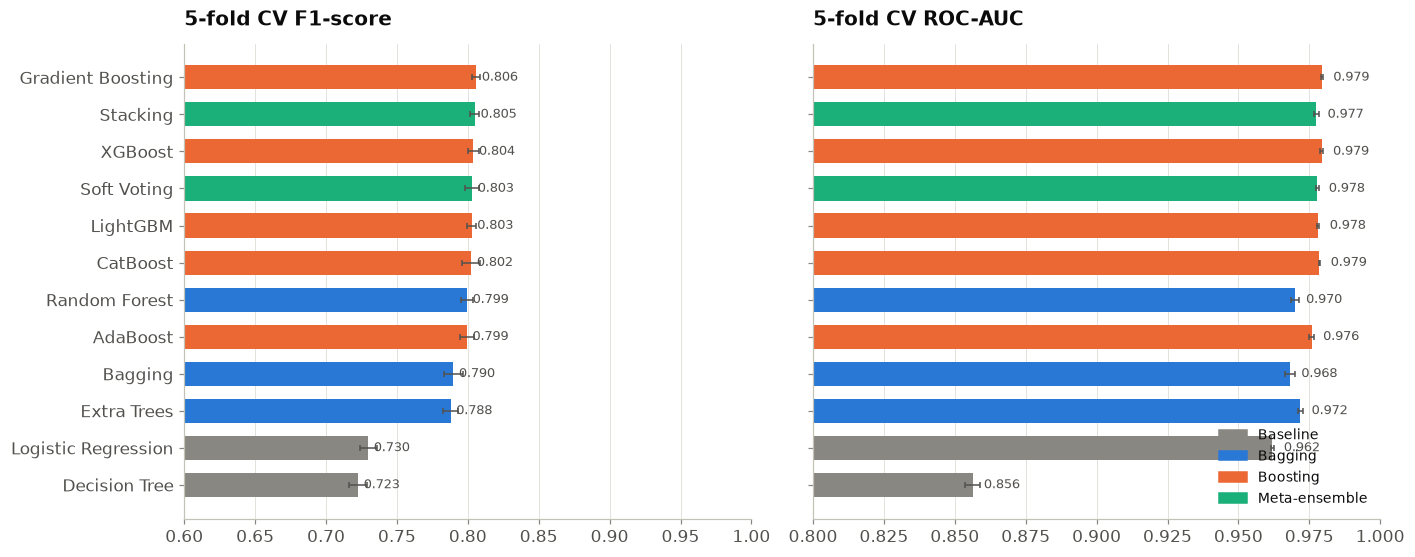

In [16]:
fam_color = {"Baseline": MUTED, "Bagging": BLUE, "Boosting": ORANGE, "Meta-ensemble": GREEN}
plot = cvres.sort_values("CV f1")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, col, err, title, lo in [(axes[0], "CV f1", "CV F1 std", "5-fold CV F1-score", 0.6),
                                (axes[1], "CV roc_auc", "CV ROC-AUC std", "5-fold CV ROC-AUC", 0.80)]:
    ax.barh(plot.Model, plot[col], xerr=plot[err], color=[fam_color[f] for f in plot.Family], height=0.65,
            error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 2})
    for yv, v in enumerate(plot[col]):
        ax.text(v + 0.004, yv, f"{v:.3f}", va="center", fontsize=8.5, color=INK_2)
    ax.set(title=title, xlim=(lo, 1.0)); ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in fam_color.values()]
axes[1].legend(handles, fam_color.keys(), loc="lower right", fontsize=9)
save(fig, "db_cv_comparison")

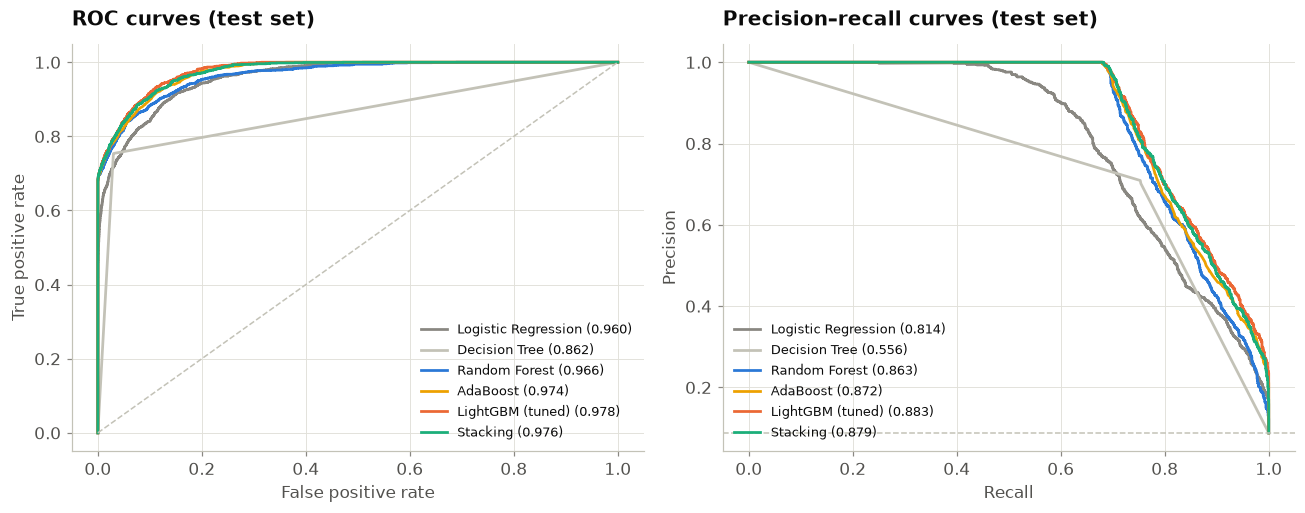

In [17]:
show = ["Logistic Regression", "Decision Tree", "Random Forest", "AdaBoost", "LightGBM (tuned)", "Stacking"]
cols = [MUTED, "#c3c2b7", BLUE, SERIES[3], ORANGE, GREEN]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for n, c in zip(show, cols):
    fpr, tpr, _ = roc_curve(y_test, proba[n])
    axes[0].plot(fpr, tpr, color=c, lw=1.8, label=f"{n} ({roc_auc_score(y_test, proba[n]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, proba[n])
    axes[1].plot(rc, pr, color=c, lw=1.8, label=f"{n} ({average_precision_score(y_test, proba[n]):.3f})")
axes[0].plot([0, 1], [0, 1], color=AXIS, ls="--", lw=1)
axes[0].set(title="ROC curves (test set)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), color=AXIS, ls="--", lw=1)
axes[1].set(title="Precision–recall curves (test set)", xlabel="Recall", ylabel="Precision")
axes[0].legend(fontsize=8.5, loc="lower right"); axes[1].legend(fontsize=8.5, loc="lower left")
save(fig, "db_roc_pr")

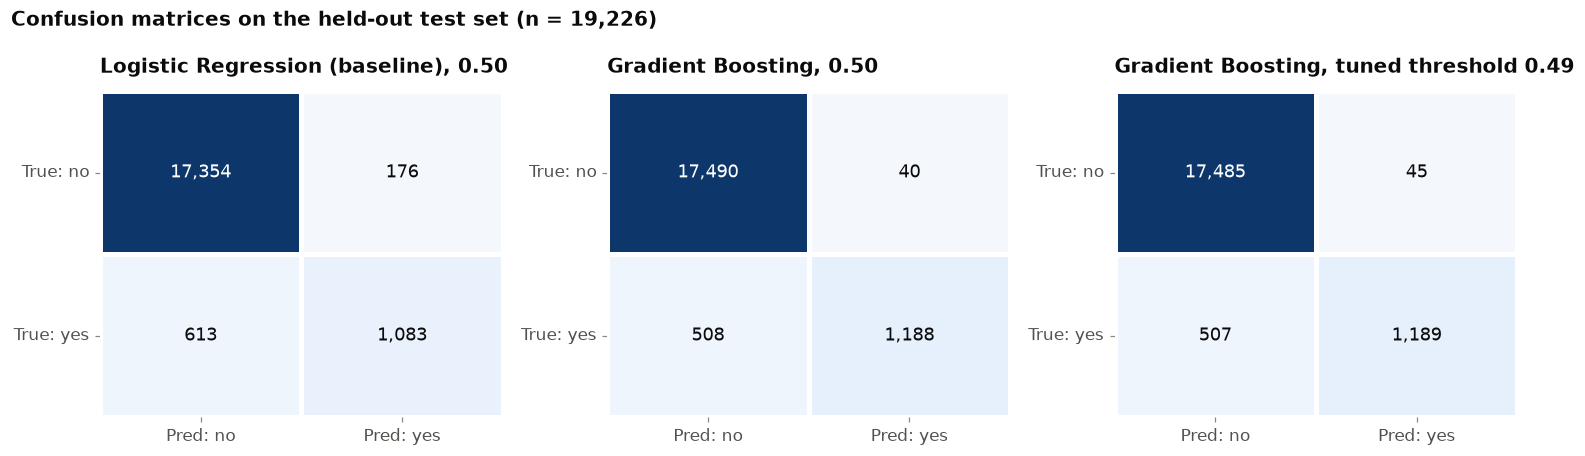

In [18]:
best_name = final_name
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (title, p, t) in zip(axes, [("Logistic Regression (baseline), 0.50", proba["Logistic Regression"], 0.5),
                                    (f"{best_name}, 0.50", proba[best_name], 0.5),
                                    (f"{best_name}, tuned threshold {thresholds[best_name]:.2f}", proba[best_name], thresholds[best_name])]):
    cm = confusion_matrix(y_test, (p >= t).astype(int))
    sns.heatmap(cm, annot=False, cmap=SEQ_BLUE, cbar=False, linewidths=2, linecolor=SURFACE, ax=ax)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j + 0.5, i + 0.5, f"{v:,}", ha="center", va="center", fontsize=12, color="white" if v > cm.max() / 2 else INK)
    ax.set_xticks([0.5, 1.5], ["Pred: no", "Pred: yes"]); ax.set_yticks([0.5, 1.5], ["True: no", "True: yes"], rotation=0)
    ax.set(title=title)
fig.suptitle(f"Confusion matrices on the held-out test set (n = {len(y_test):,})", x=0.01, ha="left", fontweight="semibold")
save(fig, "db_confusion")

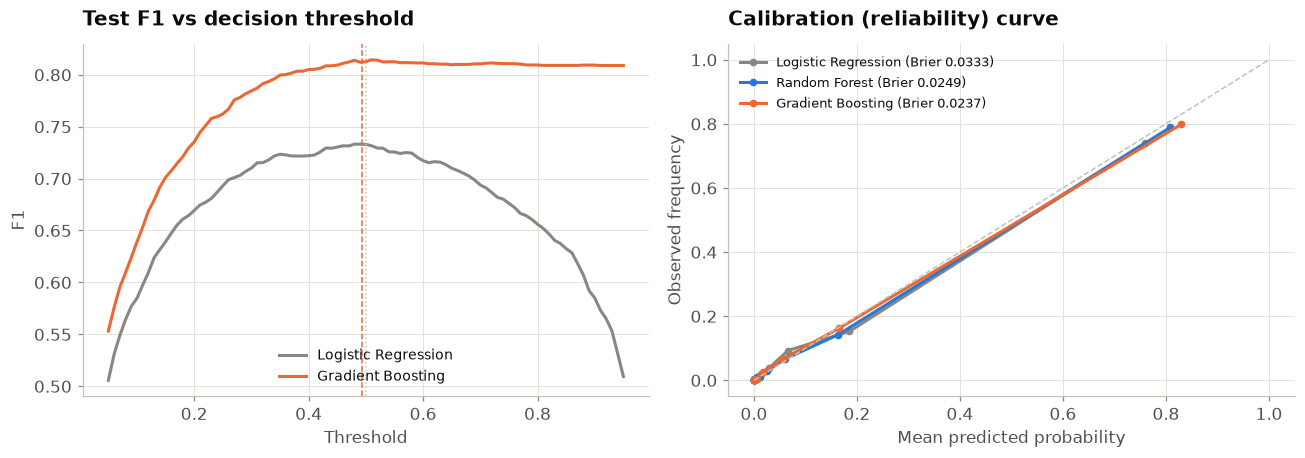

In [19]:
p_best, oof_best = proba[best_name], None
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ts = np.linspace(0.05, 0.95, 91)
for n, c in [("Logistic Regression", MUTED), (best_name, ORANGE)]:
    axes[0].plot(ts, [f1_score(y_test, (proba[n] >= t).astype(int)) for t in ts], color=c, label=n)
axes[0].axvline(0.5, color=AXIS, ls=":", lw=1)
axes[0].axvline(thresholds[best_name], color=ORANGE, ls="--", lw=1)
axes[0].set(title="Test F1 vs decision threshold", xlabel="Threshold", ylabel="F1"); axes[0].legend(fontsize=9)
for n, c in [("Logistic Regression", MUTED), ("Random Forest", BLUE), (best_name, ORANGE)]:
    fy, mx = calibration_curve(y_test, proba[n], n_bins=12, strategy="quantile")
    axes[1].plot(mx, fy, marker="o", ms=4, color=c, label=f"{n} (Brier {brier_score_loss(y_test, proba[n]):.4f})")
axes[1].plot([0, 1], [0, 1], color=AXIS, ls="--", lw=1)
axes[1].set(title="Calibration (reliability) curve", xlabel="Mean predicted probability", ylabel="Observed frequency")
axes[1].legend(fontsize=8.5)
save(fig, "db_threshold_calibration")

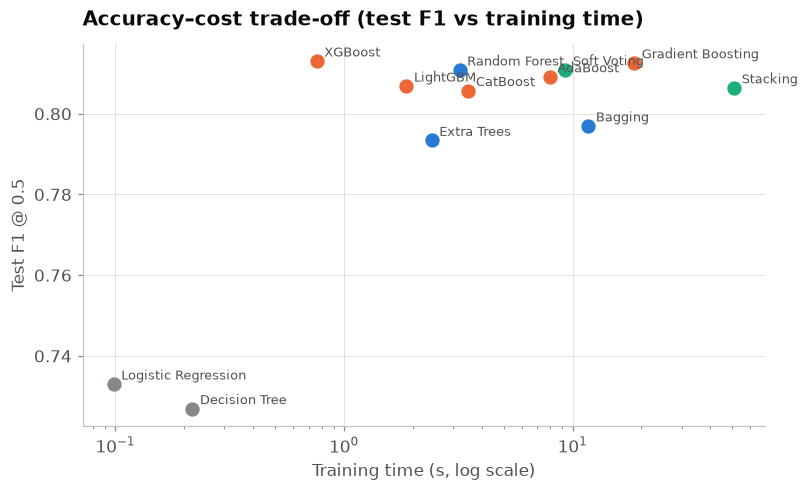

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for _, r in test.iterrows():
    ax.scatter(r["Fit time (s)"], r["F1"], s=70, color=fam_color[r.Family], zorder=3)
    ax.annotate(r.Model, (r["Fit time (s)"], r["F1"]), xytext=(5, 3), textcoords="offset points", fontsize=8.5, color=INK_2)
ax.set(xscale="log", title="Accuracy–cost trade-off (test F1 vs training time)", xlabel="Training time (s, log scale)", ylabel="Test F1 @ 0.5")
save(fig, "db_time_vs_f1")

## 11. Statistical significance
- **Paired t-test** on the 5 CV-fold F1 scores (same folds for every model).
- **McNemar's test** on the test-set predictions of the best ensemble vs Logistic Regression.

In [21]:
from scipy.stats import ttest_rel
from statsmodels.stats.contingency_tables import mcnemar
sig_rows = []
for n in [m for m in models if m != "Logistic Regression"]:
    t, pv = ttest_rel(cv_f1_folds[n], cv_f1_folds["Logistic Regression"])
    sig_rows.append({"Model": n, "Mean ΔF1 vs LR": (cv_f1_folds[n] - cv_f1_folds["Logistic Regression"]).mean(), "p-value": pv})
sig = pd.DataFrame(sig_rows).sort_values("Mean ΔF1 vs LR", ascending=False)
a = (proba[best_name] >= thresholds[best_name]).astype(int) == y_test
b = (proba["Logistic Regression"] >= 0.5).astype(int) == y_test
tbl = [[np.sum(a & b), np.sum(a & ~b)], [np.sum(~a & b), np.sum(~a & ~b)]]
mc = mcnemar(tbl, exact=False, correction=True)
print(f"McNemar ({best_name} vs Logistic Regression): only best correct {tbl[0][1]}, only LR correct {tbl[1][0]}, "
      f"chi2 = {mc.statistic:.1f}, p = {mc.pvalue:.2e}")
sig.round(5)

McNemar (Gradient Boosting vs Logistic Regression): only best correct 305, only LR correct 68, chi2 = 149.3, p = 2.44e-34


,Model,Mean ΔF1 vs LR,p-value
5,Gradient Boosting,0.07622,0.00000
10,Stacking,0.07533,0.00000
6,XGBoost,0.07416,0.00000
9,Soft Voting,0.07333,0.00000
7,LightGBM,0.07297,0.00001
8,CatBoost,0.07270,0.00000
2,Random Forest,0.06973,0.00001
4,AdaBoost,0.06959,0.00002
1,Bagging,0.06006,0.00022
3,Extra Trees,0.05817,0.00008


## 12. Interpretation: what drives the predictions? (SHAP, permutation importance, boosting dynamics)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


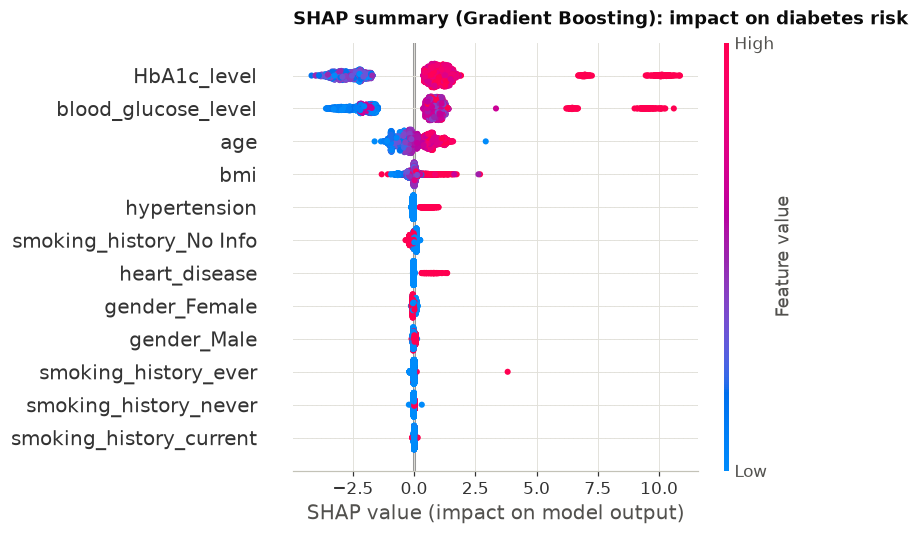

HbA1c_level                1.9236
blood_glucose_level        1.5606
age                        0.5454
bmi                        0.1894
hypertension               0.0767
smoking_history_No Info    0.0712
heart_disease              0.0523
gender_Female              0.0512
gender_Male                0.0291
smoking_history_ever       0.0137
dtype: float64

In [22]:
import shap
from sklearn.inspection import permutation_importance
shap_pipe = fitted[best_name] if FAMILY[best_name] in ("Boosting", "Bagging") else tuned   # tree model for TreeExplainer
shap_name = best_name if shap_pipe is fitted.get(best_name) else "LightGBM (tuned)"
lgb_model = shap_pipe.named_steps["model"]
Xt_test = pd.DataFrame(shap_pipe.named_steps["pre"].transform(X_test), columns=shap_pipe.named_steps["pre"].get_feature_names_out())
Xt_test.columns = [c.split("__")[1] for c in Xt_test.columns]
shap_sample = Xt_test.sample(3000, random_state=SEED)
explainer = shap.TreeExplainer(lgb_model)
sv = explainer.shap_values(shap_sample)
sv = sv[1] if isinstance(sv, list) else sv
sv = sv[:, :, 1] if sv.ndim == 3 else sv
plt.figure(figsize=(7.5, 5))
shap.summary_plot(sv, shap_sample, show=False, max_display=12, plot_size=None)
plt.title(f"SHAP summary ({shap_name}): impact on diabetes risk", loc="left", fontsize=12, fontweight="semibold")
save(plt.gcf(), "db_shap_summary")
mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=shap_sample.columns).sort_values(ascending=False)
mean_abs.head(10).round(4)

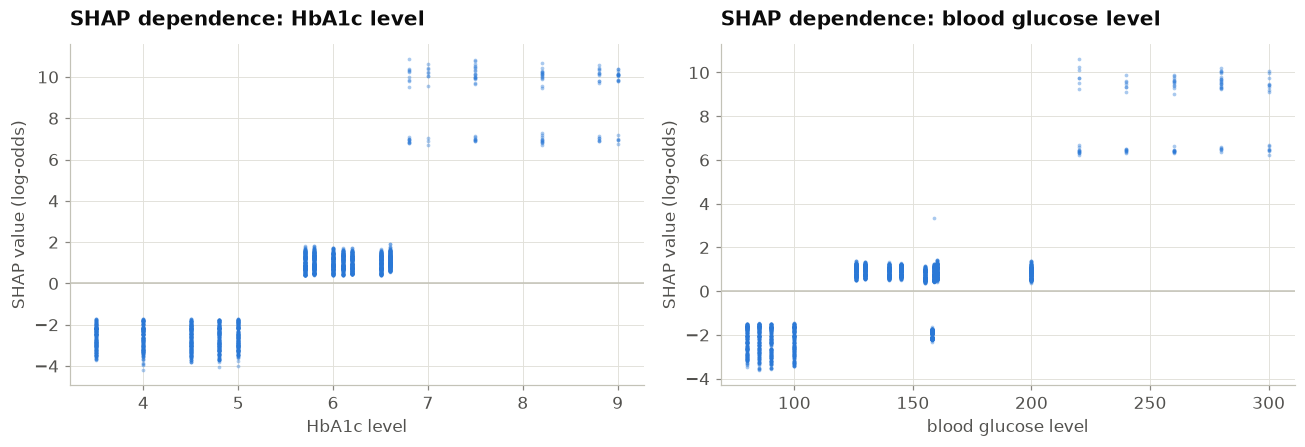

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, f in zip(axes, ["HbA1c_level", "blood_glucose_level"]):
    raw = X_test.iloc[shap_sample.index][f].values           # shap_sample keeps positional row numbers
    ax.scatter(raw, sv[:, list(shap_sample.columns).index(f)], s=6, alpha=0.4, color=BLUE, linewidths=0)
    ax.axhline(0, color=AXIS, lw=1)
    ax.set(title=f"SHAP dependence: {f.replace('_', ' ')}", xlabel=f.replace("_", " "), ylabel="SHAP value (log-odds)")
save(fig, "db_shap_dependence")

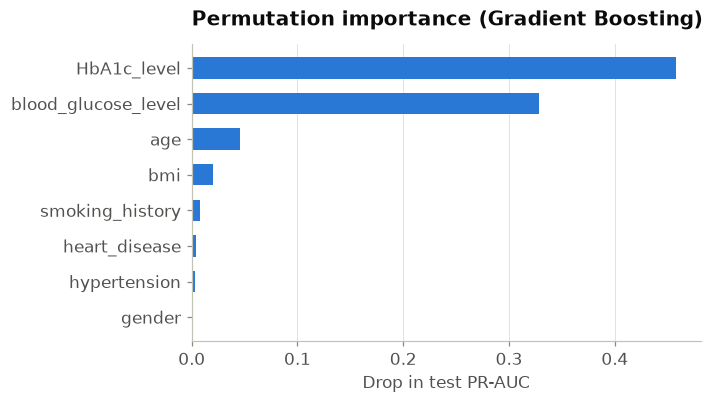

HbA1c_level            0.4583
blood_glucose_level    0.3288
age                    0.0458
bmi                    0.0199
smoking_history        0.0076
heart_disease          0.0043
hypertension           0.0031
gender                 0.0008
dtype: float64

In [24]:
perm = permutation_importance(shap_pipe, X_test, y_test, scoring="average_precision", n_repeats=10, random_state=SEED, n_jobs=1)
pi = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(6.6, 3.8))
ax.barh(pi.index, pi.values, color=BLUE, height=0.6)
ax.set(title=f"Permutation importance ({shap_name})", xlabel="Drop in test PR-AUC"); ax.grid(axis="y", visible=False)
save(fig, "db_permutation_importance")
pi.sort_values(ascending=False).round(4)

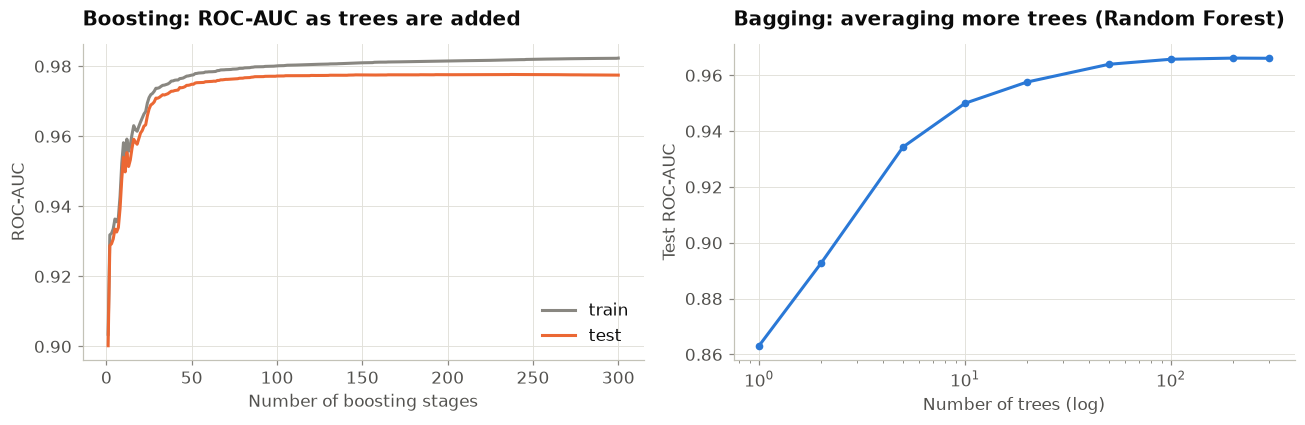

Single tree AUC 0.863 → 300 trees 0.966; GB stage 1 0.900 → 0.977


In [25]:
gb = fitted["Gradient Boosting"]; Xt_tr = gb.named_steps["pre"].transform(X_train); Xt_te = gb.named_steps["pre"].transform(X_test)
gbm = gb.named_steps["model"]
stage_tr = [roc_auc_score(y_train, p[:, 1]) for p in gbm.staged_predict_proba(Xt_tr)]
stage_te = [roc_auc_score(y_test, p[:, 1]) for p in gbm.staged_predict_proba(Xt_te)]
rf = fitted["Random Forest"].named_steps["model"]
Xr_te = fitted["Random Forest"].named_steps["pre"].transform(X_test)
tree_probs = np.array([t.predict_proba(Xr_te)[:, 1] for t in rf.estimators_])
ns = [1, 2, 5, 10, 20, 50, 100, 200, 300]
rf_auc = [roc_auc_score(y_test, tree_probs[:k].mean(axis=0)) for k in ns]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, len(stage_tr) + 1), stage_tr, color=MUTED, label="train")
axes[0].plot(range(1, len(stage_te) + 1), stage_te, color=ORANGE, label="test")
axes[0].set(title="Boosting: ROC-AUC as trees are added", xlabel="Number of boosting stages", ylabel="ROC-AUC"); axes[0].legend()
axes[1].plot(ns, rf_auc, color=BLUE, marker="o", ms=4)
axes[1].set(xscale="log", title="Bagging: averaging more trees (Random Forest)", xlabel="Number of trees (log)", ylabel="Test ROC-AUC")
save(fig, "db_ensemble_size")
print(f"Single tree AUC {rf_auc[0]:.3f} → 300 trees {rf_auc[-1]:.3f}; GB stage 1 {stage_te[0]:.3f} → {stage_te[-1]:.3f}")

## 13. Summary

In [26]:
lr_t = test.set_index("Model").loc["Logistic Regression"]; dt_t = test.set_index("Model").loc["Decision Tree"]
best_row = thr.set_index("Model").loc[best_name]
summary = {
    "rows_raw": len(df_raw), "rows_clean": len(df), "duplicates_removed": int(df_raw.duplicated().sum()),
    "prevalence": float(df.diabetes.mean()), "train": len(X_train), "test": len(X_test),
    "cv": cvres.to_dict("records"), "test_default": test.to_dict("records"), "threshold": thr.to_dict("records"),
    "best_model": best_name, "best_threshold": thresholds[best_name], "best": best_row.to_dict(),
    "best_default": test.set_index("Model").loc[best_name].to_dict(), "shap_model": shap_name,
    "tuned_params": best_params, "tuning_cv_pr_auc": float(search.best_score_), "tuning_seconds": tune_s,
    "lr_test": lr_t.to_dict(), "dt_test": dt_t.to_dict(), "significance": sig.to_dict("records"),
    "mcnemar": {"only_best_correct": int(tbl[0][1]), "only_lr_correct": int(tbl[1][0]), "chi2": float(mc.statistic), "p": float(mc.pvalue)},
    "shap_mean_abs": mean_abs.head(10).to_dict(), "perm_importance": pi.sort_values(ascending=False).to_dict(),
    "rf_auc_by_trees": dict(zip(map(str, ns), rf_auc)), "gb_stage_auc_first_last": [stage_te[0], stage_te[-1]],
    "rule_share": float(high.mean()), "rule_diabetes_rate": float(df.diabetes[high].mean()),
    "rule_capture": float(high[df.diabetes == 1].mean()),
}
save_json(summary, "diabetes_summary")
pd.Series({k: v for k, v in summary.items() if not isinstance(v, (list, dict))})

rows_raw                         100000
rows_clean                        96128
duplicates_removed                 3854
prevalence                     0.088237
train                             76902
test                              19226
best_model            Gradient Boosting
best_threshold                 0.493232
shap_model            Gradient Boosting
tuning_cv_pr_auc                0.89034
tuning_seconds                475.29699
rule_share                     0.058994
rule_diabetes_rate                  1.0
rule_capture                   0.668592
dtype: object